# 05 · Does restoration help detection?

**Kaggle · GPU T4 · Internet ON** (COCO and the YOLO weights are downloaded). About 30–45 minutes; run it as a
commit (Save Version → Save & Run All).

**The question this notebook answers:** as images get noisier, more compressed or darker, how much does a
pretrained detector's mAP drop, how much of that loss does each restoration method recover, and is the method with
the best PSNR also the one that helps detection most?

**Inputs** (right panel → Add Input → Notebooks): your committed **notebook 01** (provides `degradations.py` and
`best_classical.json`) and your committed **notebook 04** (provides `dncnn_last.pt`). The first code cell finds them
automatically.

**Design.**
- Detector: pretrained **YOLOv8n** (COCO), scored with the official `pycocotools` mAP on a fixed random subset of
  **300 COCO val2017** images. We use *val* because YOLO was trained on COCO *train*.
- Degradations: Gaussian noise (σ = 15, 25, 35, 50), JPEG (q = 70, 50, 30, 10) and low light (ℓ = 0.4, 0.6, 0.8, 0.9),
  the same functions and severities as notebook 01, so the tuned classical settings apply directly.
- Restorers: **none**, **classical** (the best tuned filter for that exact condition from notebook 01), **DnCNN**
  (trained only on Gaussian noise, so JPEG and low light are out of distribution on purpose), and for low light also
  **CLAHE on L** (the best contrast method from notebook 01, Experiment 3).
- Every restorer sees the identical degraded image (seeded by image and condition), so comparisons are paired.

**Outputs** (`/kaggle/working/outputs/05`): `detection_sweep.csv` (mAP and PSNR per condition and restorer),
`per_image_ap.csv` (used by notebook 06's failure gallery), `subset_ids.json`, and the figures.

In [1]:
!pip -q install ultralytics pycocotools

In [2]:
import os, json, random, sys, glob, time, io, contextlib
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from skimage.metrics import peak_signal_noise_ratio as sk_psnr

def find_input(name):
    """Locate a file from an attached notebook output, wherever Kaggle mounted it."""
    hits = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    assert hits, f"{name} not found under /kaggle/input: add the notebook that produced it (Add Input -> Notebooks)"
    if len(hits) > 1:
        print(f"note: {len(hits)} copies of {name}, using {hits[0]}")
    return hits[0]

DEG_PY = find_input("degradations.py")                    # from notebook 01
sys.path.insert(0, os.path.dirname(DEG_PY))
from degradations import DEGRADATIONS, degrade
BEST = json.load(open(find_input("best_classical.json")))  # from notebook 01: tuned filter per (degradation, severity)
def resolve_checkpoint():
    """Find the DnCNN checkpoint. A .pt file is a zip archive, and Kaggle unzips zip files uploaded as a
    dataset, so an uploaded dncnn_last.pt can arrive as a folder holding data.pkl. Rebuild the file if so."""
    pts = sorted(glob.glob("/kaggle/input/**/*.pt", recursive=True) + glob.glob("/kaggle/input/**/*.pth", recursive=True))
    if pts:
        return pts[0]
    pkls = sorted(glob.glob("/kaggle/input/**/data.pkl", recursive=True))
    assert pkls, "no checkpoint under /kaggle/input: attach notebook 04 (Add Input -> Your Work -> Notebooks)"
    import zipfile
    root, out = os.path.dirname(pkls[0]), "/kaggle/working/dncnn_last.pt"
    with zipfile.ZipFile(out, "w", zipfile.ZIP_STORED) as z:      # torch expects uncompressed records under one folder
        for dirpath, _, files in os.walk(root):
            for f in sorted(files):
                full = os.path.join(dirpath, f)
                z.write(full, os.path.join("archive", os.path.relpath(full, root)))
    print(f"rebuilt {out} from the unpacked folder {root}")
    return out

CKPT_PATH = resolve_checkpoint()                           # from notebook 04

N_IMAGES = 300
SEED = 0
OUT_DIR = "/kaggle/working/outputs/05"; os.makedirs(OUT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| degradations.py:", DEG_PY, "| checkpoint:", CKPT_PATH)
assert device == "cuda", "turn on Settings -> Accelerator -> GPU T4 (DnCNN on CPU would take hours)"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
rebuilt /kaggle/working/dncnn_last.pt from the unpacked folder /kaggle/input/datasets/shourjabanerjee/dcnn-last/dncnn_last
device: cuda | degradations.py: /kaggle/input/datasets/shourjabanerjee/notebook01/degradations.py | checkpoint: /kaggle/working/dncnn_last.pt


## 1 · COCO val2017 subset

Download once (images ≈ 0.8 GB, annotations ≈ 250 MB), or attach a Kaggle dataset that already has them.

In [3]:
COCO_DIR = "/kaggle/working/coco"
os.makedirs(COCO_DIR, exist_ok=True)
# Check images and annotations separately: an interrupted run can leave one without the other
if len(glob.glob(f"{COCO_DIR}/val2017/*.jpg")) < 5000:
    !rm -rf {COCO_DIR}/val2017 {COCO_DIR}/val2017.zip
    !wget -q http://images.cocodataset.org/zips/val2017.zip -O {COCO_DIR}/val2017.zip
    !unzip -q -o {COCO_DIR}/val2017.zip -d {COCO_DIR} && rm {COCO_DIR}/val2017.zip
if not os.path.exists(f"{COCO_DIR}/annotations/instances_val2017.json"):
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip -O {COCO_DIR}/ann.zip
    !unzip -q -o {COCO_DIR}/ann.zip -d {COCO_DIR} && rm {COCO_DIR}/ann.zip
n_jpg = len(glob.glob(f"{COCO_DIR}/val2017/*.jpg"))
print(n_jpg, "COCO val2017 images on disk (want 5000)")
assert n_jpg == 5000, "COCO image download incomplete: is Settings -> Internet ON? Re-run this cell"
assert os.path.exists(f"{COCO_DIR}/annotations/instances_val2017.json"), "COCO annotations missing: is Settings -> Internet ON?"

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO(f"{COCO_DIR}/annotations/instances_val2017.json")
img_ids = sorted(i for i in coco_gt.getImgIds() if len(coco_gt.getAnnIds(imgIds=i, iscrowd=False)) > 0)
random.Random(SEED).shuffle(img_ids)
img_ids = sorted(img_ids[:N_IMAGES])
json.dump(img_ids, open(f"{OUT_DIR}/subset_ids.json", "w"))   # freeze the subset: report it
n_objects = sum(len(coco_gt.getAnnIds(imgIds=i, iscrowd=False)) for i in img_ids)
print(f"{len(img_ids)} images, {n_objects} annotated objects")

5000 COCO val2017 images on disk (want 5000)
300 images, 2035 annotated objects


## 2 · Detector → COCO-format predictions

YOLO returns class indices 0–79, but COCO category ids are 1–90 with gaps. You must map them, or mAP will be
near zero for no visible reason. (Ultralytics ships a helper for this mapping — find it, or build the table
from `coco_gt.getCatIds()`.) Boxes must be `[x, y, width, height]` in original-image pixels.

In [4]:
detector = YOLO("yolov8n.pt")

# YOLO predicts class indices 0-79; COCO category ids run 1-90 with gaps (e.g. no id 12).
# YOLO's classes are COCO's 80 categories in increasing id order, so index i -> the i-th smallest id.
cat_ids = sorted(coco_gt.getCatIds())
assert len(cat_ids) == 80
coco_names = [coco_gt.loadCats(c)[0]["name"] for c in cat_ids]
mismatch = [(i, detector.names[i], coco_names[i]) for i in range(80) if detector.names[i] != coco_names[i]]
print("YOLO index -> COCO id, first five:", [(i, detector.names[i], cat_ids[i]) for i in range(5)])
print("name mismatches:", mismatch if mismatch else "none (the mapping lines up)")

def to_uint8_bgr(img):
    return (np.clip(img, 0, 1) * 255).round().astype(np.uint8)[:, :, ::-1]   # YOLO reads numpy arrays as BGR

def detect(img_rgb_float, image_id):
    """One float RGB image -> list of COCO result dicts {image_id, category_id, bbox [x, y, w, h], score}.
    conf=0.001 keeps low-confidence boxes: mAP integrates over the whole precision-recall curve, so a
    detector evaluated at a high threshold would be scored on a truncated curve."""
    r = detector.predict(np.ascontiguousarray(to_uint8_bgr(img_rgb_float)), conf=0.001, iou=0.7, max_det=300,
                         verbose=False, device=device)[0]
    xyxy = r.boxes.xyxy.cpu().numpy(); conf = r.boxes.conf.cpu().numpy(); cls = r.boxes.cls.cpu().numpy().astype(int)
    return [{"image_id": int(image_id), "category_id": int(cat_ids[c]),
             "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], "score": float(s)}
            for (x1, y1, x2, y2), s, c in zip(xyxy, conf, cls)]

def coco_map(results, ids, quiet=True):
    """(mAP@[.5:.95], mAP@.5) on exactly these image ids."""
    if not results:
        return 0.0, 0.0
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        dt = coco_gt.loadRes(results)
        E = COCOeval(coco_gt, dt, "bbox"); E.params.imgIds = list(ids)
        E.evaluate(); E.accumulate(); E.summarize()
    if not quiet:
        print(buf.getvalue())
    return float(E.stats[0]), float(E.stats[1])

def per_image_ap(results, ids):
    """AP@[.5:.95] for each image separately (for the failure gallery in notebook 06)."""
    by_img = {}
    for r in results:
        by_img.setdefault(r["image_id"], []).append(r)
    out = {}
    for iid in ids:
        out[iid] = coco_map(by_img.get(iid, []), [iid])[0] if by_img.get(iid) else 0.0
    return out

YOLO index -> COCO id, first five: [(0, 'person', 1), (1, 'bicycle', 2), (2, 'car', 3), (3, 'motorcycle', 4), (4, 'airplane', 5)]
name mismatches: none (the mapping lines up)


## 3 · Clean baseline

In [5]:
def load_coco_rgb(image_id):
    info = coco_gt.loadImgs(image_id)[0]
    return cv2.imread(f"{COCO_DIR}/val2017/{info['file_name']}", cv2.IMREAD_COLOR)[:, :, ::-1].astype(np.float32) / 255.0

t0 = time.time()
clean_results = []
for iid in img_ids:
    clean_results += detect(load_coco_rgb(iid), iid)
clean_map = coco_map(clean_results, img_ids, quiet=False)
print(f"clean mAP@[.5:.95] = {clean_map[0]:.3f}, mAP@.5 = {clean_map[1]:.3f}  ({time.time() - t0:.0f} s)")
# Sanity: YOLOv8n's published mAP@[.5:.95] on all of val2017 is 37.3. A 300-image subset will differ by a few
# points, not by 3x. Near 0 = the class-id mapping is wrong; check the mismatch line above.
assert clean_map[0] > 0.2, "clean mAP is far too low: something is wrong before any degradation is applied"

Loading and preparing results...
DONE (t=0.08s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=3.19s).
Accumulating evaluation results...
DONE (t=0.96s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.387
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.541
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.421
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.197
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.475
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.554
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.322
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.520
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.566
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

## 4 · Restoration methods

Load the DnCNN checkpoint from notebook 04 (add that notebook's Output as an input on Kaggle) and reuse your
best classical filter per degradation from notebook 01.

DnCNN was trained on Gaussian noise only, so running it on JPEG and low-light images is deliberately
**out of distribution**. Whatever happens there is a finding, not a bug — report it either way.

In [6]:
# --- DnCNN, exactly as defined in notebook 04 (the checkpoint only stores weights) ---------------
class DnCNN(nn.Module):
    def __init__(self, channels=3, depth=17, features=64):
        super().__init__()
        layers = [nn.Conv2d(channels, features, kernel_size=3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(features, features, kernel_size=3, padding=1, bias=False),
                       nn.BatchNorm2d(features), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(features, channels, kernel_size=3, padding=1)]
        self.body = nn.Sequential(*layers)
    def forward(self, y):
        return self.body(y)

ck = torch.load(CKPT_PATH, map_location=device, weights_only=False)
dncnn = DnCNN(ck["cfg"]["channels"], ck["cfg"]["depth"], ck["cfg"]["features"]).to(device)
dncnn.load_state_dict(ck["model"]); dncnn.eval()
print(f"DnCNN loaded: trained {ck['epoch'] + 1} epochs, final train loss {ck['history'][-1]:.5f}")

@torch.no_grad()
def dncnn_restore(img):
    """Full float32: under fp16 autocast some activations overflow to NaN on out-of-distribution inputs (JPEG)."""
    y = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).unsqueeze(0).to(device)
    out = (y - dncnn(y)).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy().astype(np.float32)
    assert np.isfinite(out).all(), "DnCNN produced NaN/inf"
    return out

# --- Classical filters, exactly as in notebook 01 ------------------------------------------------
def to_u8(img):  return (np.clip(img, 0, 1) * 255).round().astype(np.uint8)
def from_u8(u8): return u8.astype(np.float32) / 255.0
def f_median(img, k=3):     return from_u8(cv2.medianBlur(to_u8(img), k))
def f_gaussian(img, sigma=1.0):
    return np.clip(cv2.GaussianBlur(img.astype(np.float32), (0, 0), sigmaX=sigma, borderType=cv2.BORDER_REFLECT), 0, 1)
def f_bilateral(img, d=7, sigma_color=0.1, sigma_space=5):
    return np.clip(cv2.bilateralFilter(img.astype(np.float32), d, sigma_color, sigma_space), 0, 1)
def f_nlmeans(img, h=10):   return from_u8(cv2.fastNlMeansDenoisingColored(to_u8(img), None, h, h, 7, 21))
FILTERS = {"median": f_median, "gaussian": f_gaussian, "bilateral": f_bilateral, "nlmeans": f_nlmeans}

def classical_restore(img, name, severity):
    """The filter + parameters notebook 01 tuned for exactly this (degradation, severity)."""
    entry = BEST[name][str(severity)]
    if entry["filter"] == "none":
        return img
    return FILTERS[entry["filter"]](img, **entry["params"])

def clahe_L(img, clip=2.0, tiles=8):
    """Notebook 01, Experiment 3: CLAHE on Lab's L channel only (brightness without colour shift)."""
    lab = cv2.cvtColor(to_u8(img), cv2.COLOR_RGB2Lab)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(lab[..., 0])
    return from_u8(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))

# Conditions use notebook 01's severities, so every one has a tuned classical entry
CONDITIONS = {
    "gaussian":  [15, 25, 35, 50],
    "jpeg":      [70, 50, 30, 10],
    "low_light": [0.4, 0.6, 0.8, 0.9],
}
for name, levels in CONDITIONS.items():
    for s in levels:
        assert str(s) in BEST[name] and s in DEGRADATIONS[name][1], (name, s)

RESTORERS = {
    "none":      lambda img, name, s: img,
    "classical": classical_restore,
    "dncnn":     lambda img, name, s: dncnn_restore(img),
    "clahe_L":   lambda img, name, s: clahe_L(img),
}
APPLIES = {"gaussian": ["none", "classical", "dncnn"], "jpeg": ["none", "classical", "dncnn"],
           "low_light": ["none", "classical", "dncnn", "clahe_L"]}
print("classical filter chosen per condition:",
      {f"{n} {s}": BEST[n][str(s)]["filter"] for n, lv in CONDITIONS.items() for s in lv})

DnCNN loaded: trained 50 epochs, final train loss 0.00104
classical filter chosen per condition: {'gaussian 15': 'bilateral', 'gaussian 25': 'bilateral', 'gaussian 35': 'bilateral', 'gaussian 50': 'gaussian', 'jpeg 70': 'bilateral', 'jpeg 50': 'bilateral', 'jpeg 30': 'bilateral', 'jpeg 10': 'bilateral', 'low_light 0.4': 'gaussian', 'low_light 0.6': 'gaussian', 'low_light 0.8': 'gaussian', 'low_light 0.9': 'gaussian'}


## 5 · The main sweep

For each condition, also record PSNR between clean and restored images, so you can plot **PSNR vs mAP**.
Cache results to CSV after every condition so a disconnect doesn't cost you the run.

In [7]:
CSV = f"{OUT_DIR}/detection_sweep.csv"
rows = pd.read_csv(CSV).to_dict("records") if os.path.exists(CSV) else []
done = {(r["degradation"], r["severity"], r["restorer"]) for r in rows}
PER_IMAGE_FOR = {("gaussian", 25), ("gaussian", 50), ("jpeg", 10), ("low_light", 0.8)}   # for notebook 06
PI_CSV = f"{OUT_DIR}/per_image_ap.csv"
per_image_rows = [r for r in pd.read_csv(PI_CSV).to_dict("records") if r["degradation"] != "clean"] if os.path.exists(PI_CSV) else []

clean_imgs = {iid: load_coco_rgb(iid) for iid in img_ids}      # about 1 GB in RAM; avoids re-reading 36 times
t_start = time.time()
for name, levels in CONDITIONS.items():
    for si, s in enumerate(levels):
        sev_idx = DEGRADATIONS[name][1].index(s)
        degraded = {iid: degrade(clean_imgs[iid], name, s, np.random.default_rng([SEED, k, list(DEGRADATIONS).index(name), sev_idx]))
                    for k, iid in enumerate(img_ids)}               # identical input for every restorer
        for rname in APPLIES[name]:
            if (name, s, rname) in done:
                continue
            t0 = time.time(); results, psnrs = [], []
            for iid in img_ids:
                out = np.clip(RESTORERS[rname](degraded[iid], name, s), 0, 1).astype(np.float32)
                psnrs.append(sk_psnr(clean_imgs[iid], out, data_range=1.0))
                results += detect(out, iid)
            m, m50 = coco_map(results, img_ids)
            rows.append(dict(degradation=name, severity=s, restorer=rname, map=m, map50=m50, psnr=float(np.mean(psnrs))))
            pd.DataFrame(rows).to_csv(CSV, index=False)             # saved after every condition
            if (name, s) in PER_IMAGE_FOR:
                for (iid, ap), p in zip(per_image_ap(results, img_ids).items(), psnrs):   # same order as img_ids
                    per_image_rows.append(dict(degradation=name, severity=s, restorer=rname, image_id=iid, ap=ap, psnr=p))
                pd.DataFrame(per_image_rows).to_csv(PI_CSV, index=False)
            print(f"{name:9s} {s!s:>4} {rname:9s} mAP {m:.3f}  mAP50 {m50:.3f}  PSNR {rows[-1]['psnr']:5.2f}  ({time.time() - t0:.0f} s)")
print(f"sweep done in {(time.time() - t_start) / 60:.1f} min")

# clean per-image AP too, for the failure gallery
pd.DataFrame(per_image_rows + [dict(degradation="clean", severity=0, restorer="none", image_id=iid, ap=ap, psnr=np.nan)
                               for iid, ap in per_image_ap(clean_results, img_ids).items()]).to_csv(PI_CSV, index=False)
json.dump({"clean_map": clean_map[0], "clean_map50": clean_map[1]}, open(f"{OUT_DIR}/clean_map.json", "w"))

gaussian    15 none      mAP 0.319  mAP50 0.457  PSNR 24.94  (9 s)
gaussian    15 classical mAP 0.359  mAP50 0.508  PSNR 30.96  (17 s)
gaussian    15 dncnn     mAP 0.375  mAP50 0.526  PSNR 32.91  (32 s)
gaussian    25 none      mAP 0.241  mAP50 0.358  PSNR 20.70  (19 s)
gaussian    25 classical mAP 0.305  mAP50 0.443  PSNR 27.57  (27 s)
gaussian    25 dncnn     mAP 0.354  mAP50 0.498  PSNR 30.73  (43 s)
gaussian    35 none      mAP 0.181  mAP50 0.264  PSNR 17.97  (9 s)
gaussian    35 classical mAP 0.264  mAP50 0.389  PSNR 25.73  (17 s)
gaussian    35 dncnn     mAP 0.326  mAP50 0.464  PSNR 29.28  (34 s)
gaussian    50 none      mAP 0.088  mAP50 0.134  PSNR 15.19  (17 s)
gaussian    50 classical mAP 0.169  mAP50 0.259  PSNR 22.57  (19 s)
gaussian    50 dncnn     mAP 0.304  mAP50 0.443  PSNR 27.72  (46 s)
jpeg        70 none      mAP 0.376  mAP50 0.519  PSNR 31.54  (9 s)
jpeg        70 classical mAP 0.378  mAP50 0.525  PSNR 31.79  (17 s)
jpeg        70 dncnn     mAP 0.378  mAP50 0.525  PS

## 6 · Figures for the report

1. **mAP vs severity**, one panel per degradation, one line per restorer, with the clean mAP as a dashed line.
2. **% of lost mAP recovered** = (restored − degraded) / (clean − degraded).
3. **PSNR vs mAP scatter** across all conditions, coloured by restorer. If a method wins on PSNR but not on mAP,
   show an example image where it over-smoothed something the detector needed.
4. Per-class view (optional): which COCO classes suffer most from noise? (`E.eval['precision']` has per-class data.)

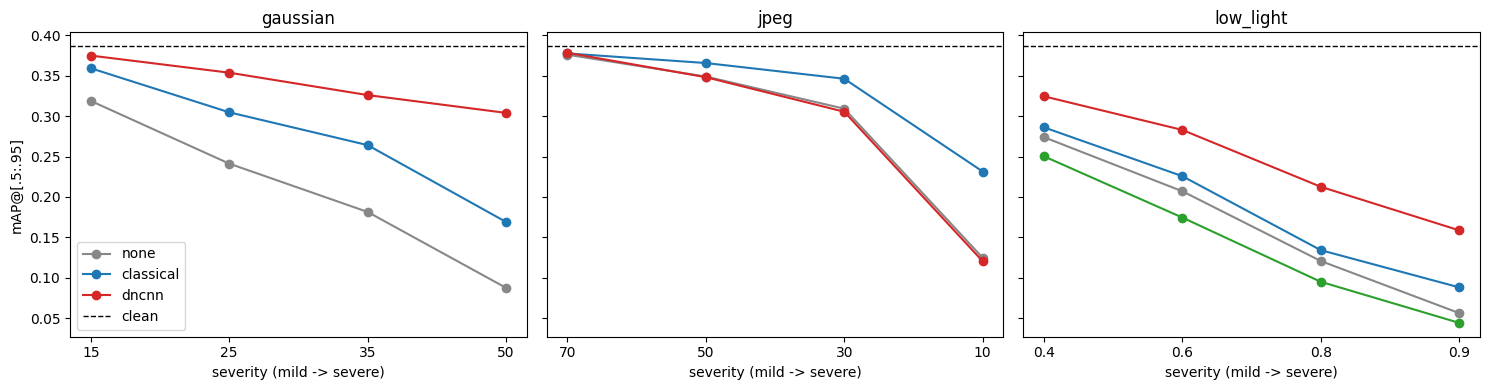

% of lost mAP recovered (100 = back to clean, 0 = no better than degraded, negative = restoration made detection worse):
restorer              clahe_L  classical  dncnn
degradation severity                           
gaussian    15.0          NaN       59.7   82.8
            25.0          NaN       43.7   77.4
            35.0          NaN       40.3   70.5
            50.0          NaN       27.3   72.4
jpeg        10.0          NaN       40.8   -1.6
            30.0          NaN       47.9   -4.9
            50.0          NaN       44.5   -2.1
            70.0          NaN       15.4   22.6
low_light   0.4         -21.0       10.8   44.9
            0.6         -18.1       10.4   42.3
            0.8          -9.7        5.1   34.5
            0.9          -3.7        9.6   31.0


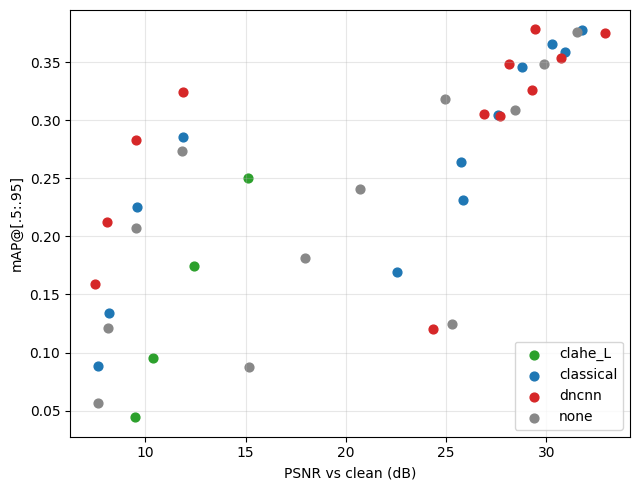


conditions where the best-PSNR restorer is NOT the best-mAP restorer: 5 of 12
  jpeg 70.0: best PSNR = classical, best mAP = dncnn
  low_light 0.4: best PSNR = clahe_L, best mAP = dncnn
  low_light 0.6: best PSNR = clahe_L, best mAP = dncnn
  low_light 0.8: best PSNR = clahe_L, best mAP = dncnn
  low_light 0.9: best PSNR = clahe_L, best mAP = dncnn
Spearman correlation between PSNR and mAP across all 40 runs: 0.82


In [8]:
df = pd.read_csv(CSV)
clean = clean_map[0]
COLORS = {"none": "#888888", "classical": "#1f77b4", "dncnn": "#d62728", "clahe_L": "#2ca02c"}
names = list(CONDITIONS)

# Figure 1: mAP vs severity
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, names):
    sub = df[df.degradation == name]
    for r in APPLIES[name]:
        s_ = sub[sub.restorer == r].set_index("severity").loc[CONDITIONS[name]]
        ax.plot([str(v) for v in CONDITIONS[name]], s_["map"], "o-", color=COLORS[r], label=r)
    ax.axhline(clean, ls="--", color="k", lw=1, label="clean")
    ax.set_title(name); ax.set_xlabel("severity (mild -> severe)")
axes[0].set_ylabel("mAP@[.5:.95]"); axes[0].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/map_vs_severity.png", dpi=150); plt.show()

# Table + Figure 2: share of the lost mAP that each restorer wins back
deg = df[df.restorer == "none"].set_index(["degradation", "severity"])["map"]
df["recovered"] = [(r.map - deg[(r.degradation, r.severity)]) / max(1e-9, clean - deg[(r.degradation, r.severity)])
                   for r in df.itertuples()]
table = df[df.restorer != "none"].pivot_table(index=["degradation", "severity"], columns="restorer", values="recovered")
print("% of lost mAP recovered (100 = back to clean, 0 = no better than degraded, negative = restoration made detection worse):")
print((table * 100).round(1).to_string())
(table * 100).round(1).to_csv(f"{OUT_DIR}/recovered_percent.csv")

# Figure 3: PSNR vs mAP. Within each condition, does the higher-PSNR restorer also get the higher mAP?
fig, ax = plt.subplots(figsize=(6.5, 5))
for r, g in df.groupby("restorer"):
    ax.scatter(g.psnr, g["map"], color=COLORS[r], label=r, s=40)
ax.set_xlabel("PSNR vs clean (dB)"); ax.set_ylabel("mAP@[.5:.95]"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/psnr_vs_map.png", dpi=150); plt.show()

disagree = []
for (name, s), g in df[df.restorer != "none"].groupby(["degradation", "severity"]):
    best_psnr, best_map = g.loc[g.psnr.idxmax(), "restorer"], g.loc[g["map"].idxmax(), "restorer"]
    if best_psnr != best_map:
        disagree.append((name, s, best_psnr, best_map))
print(f"\nconditions where the best-PSNR restorer is NOT the best-mAP restorer: {len(disagree)} of {df.groupby(['degradation', 'severity']).ngroups}")
for d in disagree:
    print(f"  {d[0]} {d[1]}: best PSNR = {d[2]}, best mAP = {d[3]}")
from scipy.stats import spearmanr
rho = spearmanr(df.psnr, df["map"]).correlation
print(f"Spearman correlation between PSNR and mAP across all {len(df)} runs: {rho:.2f}")

## 7 · What to report

1. **Clean mAP** and how fast mAP falls with each degradation (figure 1).
2. **Share of lost mAP recovered** by each restorer, per condition (table above). Expect classical filters and
   DnCNN to recover a lot on Gaussian noise, little on JPEG, and DnCNN possibly to *hurt* on low light, which is
   outside its training distribution.
3. **PSNR vs mAP**: the conditions where the best-PSNR restorer is not the best-mAP restorer are the answer to the
   research question. Pick one and show the images in notebook 06.